# FMNN25 Project 3 - Optimization

## Problem

We are trying to find the absolute minimum of functions of the form $f:\mathbb{R}^n→\mathbb{R}$.

Different optimization algorithms are used and compared including exact/inexact line search and quasi-Newton methods.

## Approximations of the Gradient and Hessian

For the gradient, central differences are used:

$$\frac{\partial f}{\partial x_i} \approx \frac{f(x + h e_i) - f(x - h e_i)}{2 h}$$

where $h$ is a small step size for numerical differentiation and $e_i$ is the $i$-th standard basis vector.

The calculation for the Hessian depends on whether a gradient function is provided:

If a gradient function $\nabla f$ **is provided**, the Hessian matrix $H$ is computed using central finite differences on the gradient vector:

$$\frac{\partial^2 f}{\partial x_i \partial x_j} \approx \frac{[\nabla f(x + h e_j)]_i - [\nabla f(x - h e_j)]_i}{2 h}$$

If **no gradient function is provided**, the Hessian is computed directly from $f(x)$ using second-order finite differences:

* **Diagonal elements ($i = j$):**

$$\frac{\partial^2 f}{\partial x_i^2} \approx \frac{f(x + h e_i) - 2f(x) + f(x - h e_i)}{h^2}$$

* **Off-diagonal elements ($i \neq j$):**

$$\frac{\partial^2 f}{\partial x_i \partial x_j} \approx \frac{f(x + h e_i + h e_j) - f(x + h e_i - h e_j) - f(x - h e_i + h e_j) + f(x - h e_i - h e_j)}{4 h^2}$$

In both cases, a symmetrization step is applied to enforce numerical symmetry:

$$H \leftarrow \frac{1}{2} (H + H^T)$$

## Newton's method

Newton's method is used to solve optimization problems iteratively by applying it on a functions, $f(x)$ gradient $\nabla f(x)$ and finding a solution to $\nabla f(x) = 0$

At each iteration $i$, evaluate the gradient $g(x_i)$ and the Hessian $G(x_i)$ at the current $x$, then solve for the full Newton step $s_i$:

$$G(x_i)\, s_i = -g(x_i) \Rightarrow s_i = - G(x_i)^{-1} g(x_i)$$

and set $x_{i+1}$ to $x_{i+1} = x_i + s_i$

### Stopping criterion
*Residual criterion*: stop when $||g(x_i)||$ is small

*Cauchy criterion* stop when $|| x_{i+1} - x_i|| = ||s_i||$ is small

### Search direction
A search direction $s$ must be a descent direction for the iteration step to reduce $f$

Criterion: If $f$ is continuously differentiable and $\nabla f(x)^T s < 0$, then $s$ is a descent direction.

This gives that $g^T s^{(k)} = -g^T G^{-1} g$ is a descent direction whenever $G_k$ is positive definite. If $G_k$ is not positive definite, the search direction may be an ascent and a back-up is needed. In our implementation the negative gradient is chosen as direction.  

## Task 5 - Newton's method on the Rosenbrock function
Find the minimum of $f(x) = 100(x_2-x_1^2)^2 + (1-x_1)^2$
using Newton's method with exact linesearch.

iteration 0
iteration 1
iteration 2
iteration 3
iteration 4
iteration 5
iteration 6
iteration 7
iteration 8
iteration 9
iteration 10
fdiff > residual_tol, fdiff: 4.662284310447403e-14
steps < max_steps, steps 11
Computed minimum: [1. 1.]
f(x): 2.0153724729353915e-25
Iterations: 11


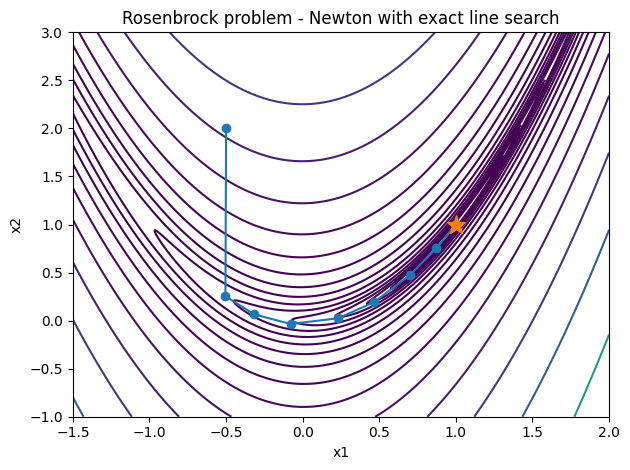

In [1]:
from rosenbrock import rosenbrock_problem
from newtons_and_linesearch_methods import NewtonWithLineSearchMethod, \
                                           test_exact_linesearch


method = NewtonWithLineSearchMethod(rosenbrock_problem)

solve_kwargs = {
    "residual_tol" : 1e-13,
    "cauchy_tol" : 1e-13,
    "max_steps" : 100
}

test_exact_linesearch(rosenbrock_problem,
                      method,
                      title="Rosenbrock problem - Newton with exact line search",
                      x0 = [-0.5, 2.0],
                      **solve_kwargs)

## Task 7 - Minimizing the Rosenbrock function with inexact line search
Find the minimum of $f(x) = 100(x_2-x_1^2)^2 + (1-x_1)^2$
using Newton's method with an inexact linesearch.

Here, using Powell-Wolfe conditions following the algorithm presented in the course lecture.

In [ ]:
self=None
def linesearch(self, dir):
    """
    Implementing a Powell-Wolfe line search based on the lecture notes.
    Note: the book by Fletcher swaps the use of sigma and rho.

    """
    phi = lambda a: self.prob(self.x + a*dir)
    phi_grad = lambda a: np.dot(self.gradient(self.x + a*dir), dir)
    f_0 = phi(0)
    f_grad_0 = phi_grad(0)

    sigma = self.sigma
    rho = self.rho
    am = self.alpha_start
    
    # Algorithm from lecture slides on optimization:

    def armijo(a):
        return phi(a) <= f_0 + sigma * a * f_grad_0

    while not armijo(am):
        am /= 2

    ap=am
    while armijo(ap):
        ap *= 2

    def powell_wolfe(a):
        return phi_grad(a) >= rho * f_grad_0

    while not powell_wolfe(am):
        a0 = (ap+am)/2
        if armijo(a0):
            am = a0
        else:
            ap = a0
    return am


iteration 0
iteration 1
iteration 2
iteration 3
iteration 4
iteration 5
iteration 6
iteration 7
iteration 8
iteration 9
iteration 10
iteration 11
iteration 12
iteration 13
fdiff > residual_tol, fdiff: 1.4227315426310912e-16
steps < max_steps, steps 14
Computed minimum: [1. 1.]
f(x): 1.4298103907130839e-30
Iterations: 14


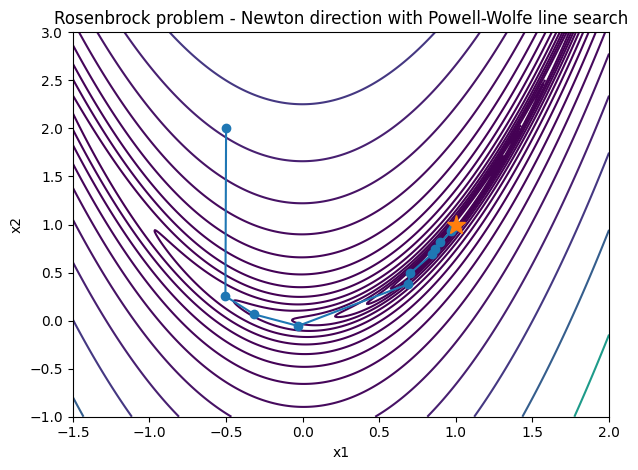

In [2]:
from rosenbrock import rosenbrock_problem
from newtons_and_linesearch_methods import NewtonWithPowellWolfe, \
                                           test_exact_linesearch

# Note: implementation here uses lecture's notation and algorithm.
# Fletcher's book uses swapped sigma and rho.
method = NewtonWithPowellWolfe(rosenbrock_problem, sigma=0.01, rho=0.1, alpha_start=1.0)

solve_kwargs = {
    "residual_tol" : 1e-13,
    "cauchy_tol" : 1e-13,
    "max_steps" : 100
}

test_exact_linesearch(rosenbrock_problem,
                      method,
                      title="Rosenbrock problem - Newton direction with Powell-Wolfe line search",
                      x0 = [-0.5, 2.0],
                      **solve_kwargs)

## Task 9

In [ ]:


from newtons_and_linesearch_methods import NewtonWithLineSearchMethod
from optproblem_class import numerical_multivariate_hessian
import numpy as np
import scipy

class QuasiNewtonMethod(NewtonWithLineSearchMethod):
    """Base class for quasi-Newton methods with line search.

    Instead of computing the Hessian, these methods maintain ``self.H``, an
    approximation of the *inverse* Hessian (initialized to the identity),
    and update it every iteration from the observed change in x and in the
    gradient. Subclasses implement :meth:`update_hessian`.

    Parameters:
        f: The optimization problem.
        *args: Passed on to the parent class.
    """
    def __init__(self, prob, verbose=True):
        super().__init__(prob, verbose)
        self.H = np.eye(self.prob.input_shape)

    def specific_solve(self):
        """Take one quasi-Newton step and update ``self.H``.

        Searches along ``-H @ g`` with a line search, then calls
        :meth:`update_hessian` with the new point. Returns the new iterate.
        """ 
        
        g = self.gradient(self.x)
        
        direction = self.find_descent_direction()
        
        # broken or non-descent direction: reset to steepest descent
        if not np.all(np.isfinite(direction)) or g @ direction >= 0:
            self.H = np.eye(self.prob.input_shape)
            direction = -g
        
        
        alfa_k = self.linesearch(direction)
        
        # line search failed with a non-trivial H: retry once with steepest descent
        if alfa_k == 0.0 and not np.allclose(self.H, np.eye(self.prob.input_shape)):
            self.H = np.eye(self.prob.input_shape)
            direction = -g
            alfa_k = self.linesearch(direction)
            
        
        x_new = self.x + alfa_k*direction
        
        self.update_hessian(x_new)
        
        if not np.all(np.isfinite(self.H)):
            self.H = np.eye(self.prob.input_shape)
        
        if self.verbose:
            print("step direction: ", direction)
            print("alpha: ", alfa_k)
            print("x: ", self.x)
            print("H: ", self.H)
        
        return x_new

    
    def update_hessian(self):
        """Update the inverse Hessian approximation ``self.H``.

        Parameters:
            x_new: The next iterate, x_{k+1}.

        Must be implemented by subclasses.
        """
        raise NotImplementedError()

    def find_descent_direction(self):
        return -self.H @ self.gradient(self.x)





class GoodBroyden(QuasiNewtonMethod):
    """Broyden's "good" method.

    Rank-one update of the inverse Hessian approximation derived from
    Broyden's secant update. The update is not symmetric, so ``H`` 
    is not guaranteed to stay symmetric or positive definite.
    """
    def __init__(self, prob, verbose=True):
            super().__init__(prob, verbose)

    def update_hessian(self, x_new):
        """Apply the good Broyden rank-one update to ``self.H``."""
        delta_k = x_new - self.x # x_(k+1) - x_k
        gamma_k = self.gradient(x_new) - self.gradient(self.x)
        numerator = delta_k@(self.H@gamma_k)
        self.H = self.H + (np.outer((delta_k - self.H@gamma_k), (delta_k@self.H))/(numerator))
        return self


class BadBroyden(QuasiNewtonMethod):
    """Broyden's "bad" method.

    Rank-one update that satisfies the secant condition ``H @ gamma = delta``
    by correcting along ``gamma``. Usually performs worse than
    :class:`GoodBroyden`; not symmetric.
    """
    def __init__(self, prob, verbose=True):
        super().__init__(prob, verbose)

    def update_hessian(self, x_new):
            """Apply the bad Broyden rank-one update to ``self.H``."""
            delta_k = x_new - self.x 
            gamma_k = self.gradient(x_new) - self.gradient(self.x)
    
            self.H = self.H + (np.outer(delta_k - self.H @ gamma_k, gamma_k)/(gamma_k@gamma_k))


class SymmetricBroyden(QuasiNewtonMethod):
    """Symmetric Broyden (SR1) method.

    Symmetric rank-one update satisfying the secant condition. ``H`` stays
    symmetric but is not guaranteed to be positive definite.
    """
    def __init__(self, prob, verbose=True):
        super().__init__(prob, verbose)

    def update_hessian(self, x_new):
        """Apply the symmetric rank-one update to ``self.H``."""
        delta_k = x_new - self.x 
        gamma_k = self.gradient(x_new) - self.gradient(self.x)

        u_k = delta_k - self.H@gamma_k
        a_k = 1/(u_k@gamma_k)
        
        self.H = self.H + a_k*np.outer(u_k, u_k)


class DFP(QuasiNewtonMethod):
    """Davidon-Fletcher-Powell (DFP) method.

    Symmetric rank-two update of the inverse Hessian approximation. ``H``
    stays positive definite as long as ``delta @ gamma > 0``, which an
    appropriate line search guarantees.
    """
    def __init__(self, prob, verbose=True):
        super().__init__(prob, verbose)

    def update_hessian(self, x_new):
        """Apply the DFP rank-two update to ``self.H``."""
        delta_k = x_new - self.x 
        gamma_k = self.gradient(x_new) - self.gradient(self.x)

        self.H = (self.H + 
                    np.outer(delta_k, delta_k)/(delta_k@gamma_k) - 
                    np.outer(self.H @ gamma_k, gamma_k @ self.H)/(gamma_k@self.H@gamma_k))


class BFGS(QuasiNewtonMethod):
    """Broyden-Fletcher-Goldfarb-Shanno (BFGS) method.

    Symmetric rank-two update of the inverse Hessian approximation. The
    most widely used quasi-Newton method: it keeps ``H`` positive definite
    when ``delta @ gamma > 0`` and is more tolerant of inexact line
    searches than :class:`DFP`."""

    def __init__(self, prob, verbose=True, test_approximation=False):
        super().__init__(prob, verbose)
        self.approx_error = []
        self.test_approximation = test_approximation

    def update_hessian(self, x_new):
        """Apply the BFGS rank-two update to ``self.H``."""
        delta_k = x_new - self.x 
        gamma_k = self.gradient(x_new) - self.gradient(self.x)

        term_1 = ((1 + (gamma_k@self.H@gamma_k)/(delta_k@gamma_k))/(delta_k@gamma_k))*np.outer(delta_k, delta_k)
        term_2 = (np.outer(delta_k,gamma_k@self.H) + np.outer(self.H@gamma_k, delta_k))/(delta_k@gamma_k)
    
        self.H = self.H + term_1 - term_2 
        # add an optional thing here
        if self.test_approximation:
            self.approx_error.append(self.test_BFGS_approx(x_new))

    def test_BFGS_approx(self, x_new):
        """
        Return the Frobenius-norm error of ``H`` versus the exact inverse Hessian at ``x_new``.
        """

        exact_H = self.hessian(x_new)
        exact_H = scipy.linalg.inv(exact_H)

        approx_error = np.linalg.norm(exact_H - self.H, 'fro')
        return approx_error
        

### Comparison of Quasi Newton methods on Chebyshev problem
n=11
residual_tol = 1e-13
cauchy_tol = 1e-13


| Method |Update type|H positive-definite|Iterations|f| Execution Time (s) | Exec Time per iter (s) |
|-------:|--:|--:|-----:|--|-----:|---:|
|Good Broyden|Rank-1, non-symmetric|Not guaranteed|136|0.00300826592|3.41|0.0250| 
|Bad Broyden|Rank-1 non-symmetric|Not guaranteed|57|0.00279976180|1.40|0.02460|
|Symmetric Broyden|Rank-1, symmetric|Not guaranteed|41| 0.00279976155|1.01|0.02468|
|DFP|Rank-2, symmetric|Yes, if sᵀy > 0|30|0.00279976155|0.81|0.0272|
|BFGS|Rank-2, symmetric|Yes, if sᵀy > 0|30| 0.00279976155|0.74|0.0248|

DFP and BFGS performed best on the Chebyshev problem (n=11), reaching the lower minimum in 30 iterations. Symmetric and Bad Broyden ended at the same minimum in 41 nd 57 iterations, whilst Good Broyden ended at the higher minimum.

Rank-2 updates converged faster than rank-1. Time per iteration was similiar for all, and the execution time follows the number of iterations.

## Task 11

Compare our implemented optimization methods and the scipy implemented BFGS on the Chebyquad problem.

In [1]:
import scipy
import numpy as np
from time import perf_counter_ns
from optproblem_class import OptProblem
from chebyquad_problem import chebyquad, gradchebyquad
from quasinewton_methods import BFGS, DFP, SymmetricBroyden, BadBroyden, GoodBroyden
from newtons_and_linesearch_methods import NewtonsMethod, NewtonWithLineSearchMethod, NewtonWithPowellWolfe

n_methods = []
n_sols = []

for n in (4,8,11):
    prob = OptProblem(
        chebyquad,
        input_shape=n,
        grad=gradchebyquad
    )
    method_kwargs = {
        "prob": prob,
        "verbose": False
    }

    methods = {
        "Good Broyden" : GoodBroyden(**method_kwargs),
        "Bad Broyden" : BadBroyden(**method_kwargs),
        "Symmetric Broyden" : SymmetricBroyden(**method_kwargs),
        "DFP" : DFP(**method_kwargs),
        "BFGS" : BFGS(**method_kwargs),
        "Newton" : NewtonsMethod(**method_kwargs),
        "Newton exact ls" : NewtonWithLineSearchMethod(**method_kwargs),
        "Newton PW ls": NewtonWithPowellWolfe(
                                            sigma=0.01,
                                            rho=0.1,
                                            alpha_start=1.0,
                                            **method_kwargs)
    }
    n_methods.append(methods)

    x0 = np.linspace(0,1,n)

    solve_kwargs = {
        "x0" : x0,
        "residual_tol" : 1e-13,
        "cauchy_tol" : 1e-13,
        "max_steps" : 100
    }

    solutions = {k:m.solve(**solve_kwargs) for k,m in methods.items()}
    n_sols.append(solutions)

    # include scipy bfgs:
    scipy_time = perf_counter_ns()
    solutions["scipy BFGS"] = scipy.optimize.fmin_bfgs(
        prob.f,
        x0,
        fprime=prob.grad,
        disp=False,
        maxiter=500,
        )
    scipy_time = perf_counter_ns() - scipy_time

    print("\n"*3 + "*"*40)
    print("*"*10 + f"{f' Done with n={n}!':^20}" + "*"*10)
    print("*"*40 + "\n")

    with np.printoptions(linewidth=200):
        print(f"\n{'name':<18} | {'its':<3} | {'t(s)':<6} | {'f':<10} | x")
        for k,x in solutions.items():
            iters = f"{methods[k].steps}" if k in methods else ""
            exec_time = sum(methods[k].exec_time_history) if k in methods else scipy_time
            exec_time *= 10**-9
            # exec_time = f"{sum(methods[k].exec_time_history)*10**-9:.3f}" if k in methods else ""
            print(f"{k:<18} | {iters:<3} | {exec_time:<6.3f} | {prob(x):<10.3e} | {x}")





****************************************
**********   Done with n=4!   **********
****************************************


name               | its | t(s)   | f          | x
Good Broyden       | 2   | 0.002  | 4.326e-30  | [0.88729833 0.62909944 0.37090056 0.11270167]
Bad Broyden        | 2   | 0.001  | 4.326e-30  | [0.88729833 0.62909944 0.37090056 0.11270167]
Symmetric Broyden  | 2   | 0.001  | 4.326e-30  | [0.88729833 0.62909944 0.37090056 0.11270167]
DFP                | 2   | 0.001  | 4.326e-30  | [0.88729833 0.62909944 0.37090056 0.11270167]
BFGS               | 2   | 0.001  | 4.326e-30  | [0.88729833 0.62909944 0.37090056 0.11270167]
Newton             | 5   | 0.001  | 2.901e-29  | [0.11270165 0.3709006  0.6290994  0.88729835]
Newton exact ls    | 2   | 0.002  | 5.722e-21  | [0.11270304 0.37089643 0.62910357 0.88729696]
Newton PW ls       | 5   | 0.001  | 5.561e-27  | [0.11270166 0.37090056 0.62909944 0.88729834]
scipy BFGS         |     | 0.001  | 3.462e-14  | [0.11270161 

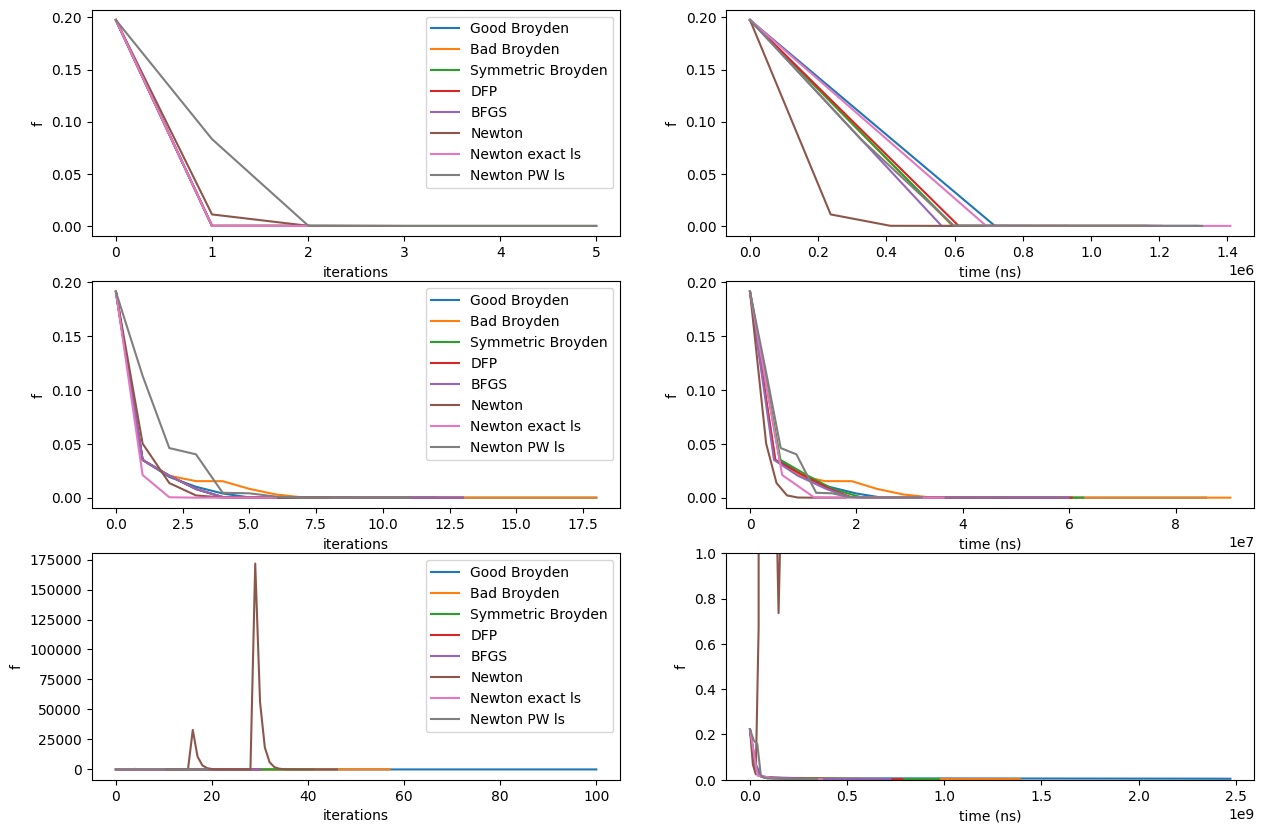

In [4]:
import matplotlib.pyplot as plt
from optmethods_baseclass import OptMethod

def plot_conv(n_methods: dict[str,OptMethod]):
    fig, axes = plt.subplots(len(n_methods), 2, figsize=(15,10))

    for row, methods in enumerate(n_methods):
        for name, m in methods.items():
            # plot iterations v. function value
            axes[row,0].plot(range(m.steps+1), m.f_history, label=name)

            # plot time v. function value
            if row < len(n_methods)-1:
                axes[row,1].plot(np.cumsum(m.exec_time_history), m.f_history, label=name)
            else:
                axes[row,1].plot(np.cumsum(m.exec_time_history), m.f_history, label=name)
                axes[row,1].set_ylim(0,1)

        axes[row,0].set_ylabel("f")
        axes[row,0].set_xlabel("iterations")
        axes[row,0].legend()
        axes[row,1].set_ylabel("f")
        axes[row,1].set_xlabel("time (ns)")


plot_conv(n_methods)

## Task 12

Study the approximation quality of the BFGS method's estimated inverse Hessian.

[np.float64(2.515902068499186), np.float64(7.287798814970933), np.float64(2.512006359344893), np.float64(2.6770883693599767), np.float64(6.413123245075634), np.float64(7.000666009387311), np.float64(83.2487132271847), np.float64(11305.008828788707), np.float64(12149.78840418033), np.float64(34233.86642839035), np.float64(40273.15507124844), np.float64(10118976.086862871), np.float64(30812227.948857684)]


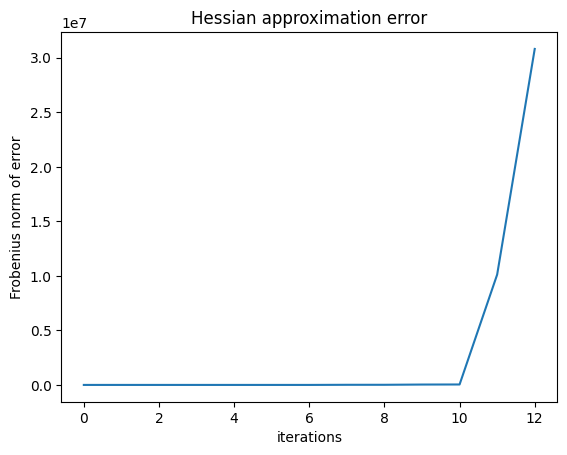

In [5]:
from rosenbrock import rosenbrock_problem
from chebyquad_problem import chebyquad, gradchebyquad
from optproblem_class import OptProblem
from quasinewton_methods import BFGS
import numpy as np
import matplotlib.pyplot as plt

# prob = rosenbrock_problem
# cheby is not working right with scipy.diff.hessian, mismatching dimensions in scipy Hessian estimation.
prob = OptProblem(chebyquad, 8, grad=gradchebyquad)

met = BFGS(prob, verbose=False, test_approximation=True)

met.solve(np.linspace(0,1,prob.input_shape), 1e-16, 1e-16, 50)

print(met.approx_error)

plt.plot(met.approx_error)
plt.title("Hessian approximation error")
plt.xlabel("iterations")
plt.ylabel("Frobenius norm of error")
plt.show()